# Demand Calculations
In this notebook, we calculate state level demand for each byproduct across its key marketable end-uses.

In [145]:
import pandas as pd
import numpy as np
import geopandas as gpd
import math

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.transforms import ScaledTranslation
import seaborn as sns
from cmcrameri import cm

from molmass import Formula

import requests

# add main repo directory to path
import sys
import os
sys.path.append(os.path.abspath('..'))

# add submodules to path
sys.path.append('../submodules/gw-avail-and-comp')

# set up figure style in same way as gw-avail-and-comp repo
from project_utils import setup_figure_style, subscript_numbers, get_boundaries, project_crs
setup_figure_style()

# Load Data

In [146]:
# state geodataframe

######################################################################
######## TEST IF GET_BOUNDARIES() WORKS FOR STATE BOUNDARIES #########
######################################################################

url = 'https://www2.census.gov/geo/tiger/TIGER2025/STATE/tl_2025_us_state.zip'

# send request and check response status
response = requests.get(url)
if response.status_code != 200:
    response.raise_for_status()

# read file from link
st_df = gpd.read_file(url).to_crs(project_crs)

# repair invalid geometries
st_df['geometry'] = st_df['geometry'].make_valid()

# extract largest polygon (mainland)
mainland_gdf = st_df.dissolve().explode(index_parts=True).reset_index(drop=True)
mainland_poly = mainland_gdf.geometry.loc[mainland_gdf.geometry.area.idxmax()]

# clip original gdf to mainland
st_df = st_df.clip(mainland_poly)

# # state geodataframe
# st_df = get_boundaries('state')
st_df.drop(index=st_df[st_df['STUSPS']=='DC'].index, inplace=True)
st_df = st_df.sort_values(by='NAME').reset_index(drop=True)

In [147]:
# load market and demand pricing data
demand_path = '../data/demand_calculations.xlsx'

# market - collapse by end use category
market_df = pd.read_excel(demand_path, sheet_name = 'X1. Markets', na_values=['–'])
market_df = market_df.groupby(['byproduct', 'end_use_category'], as_index=False).agg({'pct_demand': lambda x: x.sum(skipna=False)})

# demand
bpd_df = pd.read_excel(demand_path, sheet_name = 'X2. BP x Domestic', na_values=['–'])
bpms_df = pd.read_excel(demand_path, sheet_name = 'X3. BP-Market x State', na_values=['–'])

In [148]:
# disaggregation proxies
proxy_path = '../data/disaggregation_proxies.xlsx'
proxy_dict = pd.read_excel(proxy_path, sheet_name=None, header=3, usecols='B:E', nrows=48)

# identify proxies to be used for each end use category
market_to_proxy_dict = {
    # Manufacturing
    'Cement Manufacturing' : 'cement_production',
    'Lime Manufacturing' : 'lime_manufacturing',
    'Glass Manufacturing' : 'glass_emissions',
    'Borosilicate Glass Manufacturing' : 'mineral_wool', # NEED A NEW PROXY HERE
    'Gypsum-Based Product Manufacturing' : 'gypsum_facilities',
    'Steel Pickling' : 'steel_pickling_facilities',
    'Pulp and Paper Manufacturing' : 'pulp_and_paper_facilities',
    'Semiconductor Manufacturing' : 'semiconductor_employment',
    'Lithium Battery Manufacturing' : 'lithium_battery_production',
    'Cosmetics and Personal Care Product Manufacturing' : 'cosmetics_employment',
    'Organic Chemical Manufacturing' : 'org_chemical_manufacturing',
    'Pharmaceutical Manufacturing' : 'pharma_manufacturing',
    'Hydrofluoric Acid Manufacturing' : 'hf_production_capacity',
    'Phosphoric Acid Manufacturing' : 'phosphoric_acid_facilities',
    'Nitrogenous Fertilizer Manufacturing' : 'ammonia_production_capacity',
    'Miscellaneous Chemical Manufacturing' : 'chemical_manufacturing',
    'Miscellaneous Manufacturing' : 'manufacturing',

    # Utilities and Infrastructure
    'Industrial Water Treatment' : 'industrial_water_use',
    'Drinking Water Treatment' : 'public_supply_water_use',
    'Wastewater Treatment' : 'wwtp_flow',
    'Deicing and Dust Control' : 'rock_salt_distribution',
    'Miscellaneous Construction' : 'construction_spending',

    # Energy and Electricity
    'Oil and Gas Drilling' : 'oil_and_gas_wells',
    'Oil and Gas Well Acidification' : 'oil_and_gas_wells',
    'Flue Gas Desulfurization' : 'flue_gas_desulfurization',

    # Agriculture
    'Potash Fertilizer Application' : 'potash_fertilizer_consumption',
    'Nitrogenous Fertilizer Application' : 'nitrogen_fertilizer_consumption',
    'Soil Additive' : 'crop_acreage',
    'Miscellaneous Fertilizer Application' : 'crop_acreage',


    ######################################
    ######################################
    ######################################
    ######################################
    ######################################
    # Unused - DELETE BEFORE PUBLICATION AND DELETE CORRESPONDING SHEETS IN EXCEL
    'Iron and Steel Manufacturing' : 'iron_and_steel_employment',
    'Miscellaneous Metallurgy' : 'metallurgy_employment',
    'Metal Ore Leaching' : 'ore_treated',
    'Phosphatic Fertilizer Manufacturing' : 'phosphate_fertilizer_facilities',
    'Pesticide Manufacturing' : 'pesticide_employment',
    'Alumina Refining' : 'alumina_refining_capacity',
    ######################################
    ######################################
    ######################################
    ######################################
    ######################################
}

print('Proxies by End-Use Category:')
for market, proxy in market_to_proxy_dict.items():
    print(f' - {market}: {proxy}')

print('\nOther Availalbe Proxies:')
for proxy in proxy_dict.keys():
    if proxy not in market_to_proxy_dict.values():
        print(f' - {proxy}')

Proxies by End-Use Category:
 - Cement Manufacturing: cement_production
 - Lime Manufacturing: lime_manufacturing
 - Glass Manufacturing: glass_emissions
 - Borosilicate Glass Manufacturing: mineral_wool
 - Gypsum-Based Product Manufacturing: gypsum_facilities
 - Steel Pickling: steel_pickling_facilities
 - Pulp and Paper Manufacturing: pulp_and_paper_facilities
 - Semiconductor Manufacturing: semiconductor_employment
 - Lithium Battery Manufacturing: lithium_battery_production
 - Cosmetics and Personal Care Product Manufacturing: cosmetics_employment
 - Organic Chemical Manufacturing: org_chemical_manufacturing
 - Pharmaceutical Manufacturing: pharma_manufacturing
 - Hydrofluoric Acid Manufacturing: hf_production_capacity
 - Phosphoric Acid Manufacturing: phosphoric_acid_facilities
 - Nitrogenous Fertilizer Manufacturing: ammonia_production_capacity
 - Miscellaneous Chemical Manufacturing: chemical_manufacturing
 - Miscellaneous Manufacturing: manufacturing
 - Industrial Water Treatme

# Helper Functions and Variables

In [149]:
# dictionary mapping each byproduct to its demand data specificity and resolution
calc_method_dict = dict.fromkeys(market_df['byproduct'].unique(), 'Byproduct x Domestic')
calc_method_dict.update(dict.fromkeys(bpms_df['byproduct'].unique(), 'Byproduct-Market x State'))
calc_method_dict

{'B': 'Byproduct x Domestic',
 'BaSO4': 'Byproduct x Domestic',
 'Br': 'Byproduct x Domestic',
 'Ca(OH)2': 'Byproduct x Domestic',
 'CaCO3': 'Byproduct-Market x State',
 'CaF2': 'Byproduct x Domestic',
 'CaSO4': 'Byproduct x Domestic',
 'HCl': 'Byproduct x Domestic',
 'HF': 'Byproduct x Domestic',
 'K2O': 'Byproduct x Domestic',
 'Li': 'Byproduct x Domestic',
 'Mg(OH)2': 'Byproduct x Domestic',
 'MgCl2': 'Byproduct-Market x State',
 'MgSO4': 'Byproduct x Domestic',
 'NH3': 'Byproduct x Domestic',
 'Na2CO3': 'Byproduct x Domestic',
 'NaCl': 'Byproduct x Domestic',
 'NaOH': 'Byproduct x Domestic',
 'P2O5': 'Byproduct x Domestic',
 'SrSO4': 'Byproduct x Domestic'}

In [150]:
# demand columns
demand_cols = ['demand_2021_kt', 'demand_2022_kt', 'demand_2023_kt', 'demand_2024_kt', 'demand_2025_kt']

In [151]:
# dictionary mapping state names to state alphas
state_name_to_alpha_dict = dict(zip(st_df['NAME'], st_df['STUSPS']))

In [152]:
def calculate_state_demand(bp, market, demand):
    """
    Calculates the demand for a given byproduct in a given market for all
    states in CONUS using the methods specified in methods_dict. Returns a Series with
    the results.

    Arguments:
    bp : str
        The byproduct for which to calculate demand.
    market : str
        The market for which to calculate demand.
    
    Returns:
    state_demand : pd.DataFrame
        A DataFrame with the estimated state-level demand for the byproduct in the specified marke 
        for each year 2021-2025.
    
    """
    # create a dataframe to hold state-level demand results
    state_demand = pd.DataFrame(index=st_df['STUSPS'], columns=demand_cols)

    # identify calculation method based on byproduct
    calc_method = calc_method_dict[bp]

    # Method #1: Byproduct x Domestic
    if calc_method == 'Byproduct x Domestic':
        # get demand data for this byproduct from bpd_df
        bp_demand = bpd_df.loc[bpd_df['byproduct']==bp][demand_cols].iloc[0].copy()

        # get market share from market_df
        market_share = market_df.loc[(market_df['byproduct']==bp) & (market_df['end_use_category']==market), 'pct_demand'].iloc[0].copy()

        # byproduct-market demand = domestic demand * market share
        bpm_demand = bp_demand * market_share

        # disaggregate to state-level using proxy
        try:
            proxy = market_to_proxy_dict[market]
        except KeyError:
            raise ValueError(f"No proxy found for market: {market}")

        proxy_df = proxy_dict[proxy]
        proxy_df = proxy_df.set_index('State Alpha')
        state_shares = proxy_df.loc[state_demand.index, 'Percent of Total']
        state_demand[demand_cols] = state_shares.values[:, np.newaxis] * bpm_demand[demand_cols].values

    # Method #2: Byproduct-Market x State
    elif calc_method == 'Byproduct-Market x State':
        # get state-level demand data for this byproduc-market from bpms_df
        bpms_demand = bpms_df.loc[(bpms_df['byproduct']==bp) & (bpms_df['end_use_category']==market)].set_index('state', drop=True).copy()

        # get total withheld quantities for each year
        totals_withheld = bpms_demand.loc['Total Withheld', demand_cols].copy()

        # drop rows for states outside of conus
        bpms_demand = bpms_demand[bpms_demand.index.isin(st_df['NAME'])].copy()
        bpms_demand.index = bpms_demand.index.map(state_name_to_alpha_dict)

        # iterate through each year and fill in state_demand
        for col in demand_cols:
            # use state-level demand data directly
            state_demand[col] = bpms_demand.loc[state_demand.index, col]

            # get the total withheld quantity
            total_withheld = totals_withheld[col]

            # see if any quantity has been withheld
            if total_withheld > 0:
                
                # get the states with missing demand data
                missing_states = bpms_demand[bpms_demand[col]=='W'].index.tolist()
            
                # get the proxy for this market
                proxy = market_to_proxy_dict[market]
                proxy_df = proxy_dict[proxy]
                proxy_df = proxy_df.set_index('State Alpha')

                # isolate the proxy data for the missing states
                w_proxy_df = proxy_df.loc[missing_states].copy()
                w_proxy_df['Percent of Total'] = w_proxy_df['Metric Value'] / w_proxy_df['Metric Value'].sum() # recalculate percent of total for states with withheld data

                for state in missing_states:
                    # calculate the state-level demand for the withheld quantity using the proxy
                    state_demand.loc[state, col] = w_proxy_df.loc[state, 'Percent of Total'] * total_withheld

    else:
        raise ValueError(f"Unknown calculation method: {calc_method}")
    
    # cast all demand values to float
    state_demand = state_demand.astype(float)
    
    return state_demand
            

In [157]:
# dictionary to store results
demand_dict = {}

# Calculate Demand

In [160]:
# iterate through byproducts and markets to calculate state-level demand
for bp in market_df['byproduct'].unique():
    print(f'========== {bp} ==========')
    bp_markets = market_df.loc[market_df['byproduct']==bp, 'end_use_category'].values
    demand_dict[bp] = {}
    print(f'\t End Use Categories:')
    for market in bp_markets:
        print(f'\t\t - {market} ({100*market_df[(market_df["byproduct"]==bp) & (market_df["end_use_category"]==market)]["pct_demand"].values[0]:.1f}%)')
        if market == 'Other':
            continue
        state_demand = calculate_state_demand(bp, market, demand_cols)
        demand_dict[bp][market] = state_demand


========== B ==========
	 End Use Categories:
		 - Borosilicate Glass Manufacturing (65.0%)
		 - Miscellaneous Manufacturing (35.0%)
========== BaSO4 ==========
	 End Use Categories:
		 - Miscellaneous Manufacturing (10.0%)
		 - Oil and Gas Drilling (90.0%)
========== Br ==========
	 End Use Categories:
		 - Industrial Water Treatment (8.4%)
		 - Miscellaneous Chemical Manufacturing (58.9%)
		 - Oil and Gas Drilling (12.6%)
		 - Organic Chemical Manufacturing (10.5%)
		 - Pharmaceutical Manufacturing (9.5%)
========== Ca(OH)2 ==========
	 End Use Categories:
		 - Drinking Water Treatment (5.6%)
		 - Flue Gas Desulfurization (18.1%)
		 - Miscellaneous Chemical Manufacturing (24.9%)
		 - Miscellaneous Construction (35.6%)
		 - Other (10.6%)
		 - Wastewater Treatment (5.2%)
========== CaCO3 ==========
	 End Use Categories:
		 - Cement Manufacturing (15.7%)
		 - Lime Manufacturing (4.6%)
		 - Other (79.7%)
========== CaF2 ==========
	 End Use Categories:
		 - Hydrofluoric Acid Manufacturin

# Visualization

In [162]:
def plot_demand_results(bp):
    """
    Plots the state-level demand results for a given byproduct across all markets.

    Arguments:
    bp : str
        The byproduct for which to plot demand results.
    
    Returns:
    fig : matplotlib.figure.Figure
        The figure object containing the subplots.
    axs : numpy.ndarray
        The array of axes objects for the subplots.
    cbar : matplotlib.colorbar.Colorbar
        The colorbar object for the figure.

    """
    bp_markets = demand_dict[bp].keys()

    # get absolute minimum and maximum demand values across all markets for this byproduct
    min_demand = min([demand_dict[bp][market].min().min() for market in bp_markets])
    max_demand = max([demand_dict[bp][market].max().max() for market in bp_markets])
    norm = Normalize(vmin=min_demand, vmax=max_demand)

    # set up figure
    nrows = len(bp_markets)
    ncols = 5 # number of years
    fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5*ncols, 4*nrows), constrained_layout=True)
    for ax in axs.flatten():
        ax.axis('off')

    # plot
    for i, market in enumerate(bp_markets):
        # get state-level demand for this byproduct-market
        state_demand = demand_dict[bp][market]
        if state_demand is None:
            continue

        # merge state-level demand with state geodataframe
        merged_gdf = st_df.merge(state_demand, left_on='STUSPS', right_index=True)

        # plot each year
        for j, col in enumerate(demand_cols):
            ax = axs[i, j]
            ax.set_title(f'{j+2021}', fontsize=24, y=0.95)

            merged_gdf.plot(column=col, cmap='rocket_r', norm=norm, ax=axs[i,j], legend=False, edgecolor='black', linewidth=0.5)

    # label rows with market names in figure coordinates so they don't affect subplot sizing
    fig.canvas.draw()
    for i, market in enumerate(bp_markets):
        pos = axs[i, 0].get_position()
        offset = ScaledTranslation(0, 30/72, fig.dpi_scale_trans)
        fig.text(pos.x0, pos.y1, market, fontsize=28, ha='left', va='bottom',
                transform=fig.transFigure + offset)

    # add single colorbar to the right for all subplots
    map_top = axs[0, 0].get_position().y1
    map_bottom = axs[-1, 0].get_position().y0

    cbar_ax = fig.add_axes([1.0, map_bottom, 0.02, map_top - map_bottom])
    sm = plt.cm.ScalarMappable(cmap='rocket_r', norm=norm)
    cbar = fig.colorbar(sm, cax=cbar_ax)
    cbar.set_label('Demand (kt)', rotation=270, fontsize=24, labelpad=30)
    cbar.ax.tick_params(labelsize=20)

    # suptitle
    offset = ScaledTranslation(0, 16/72, fig.dpi_scale_trans)
    fig.text(0.5, 1.0, f'Demand for {subscript_numbers(bp)} by Market and Year',
            fontsize=32, ha='center', va='bottom',
            transform=fig.transFigure + offset)

    return fig, axs, cbar

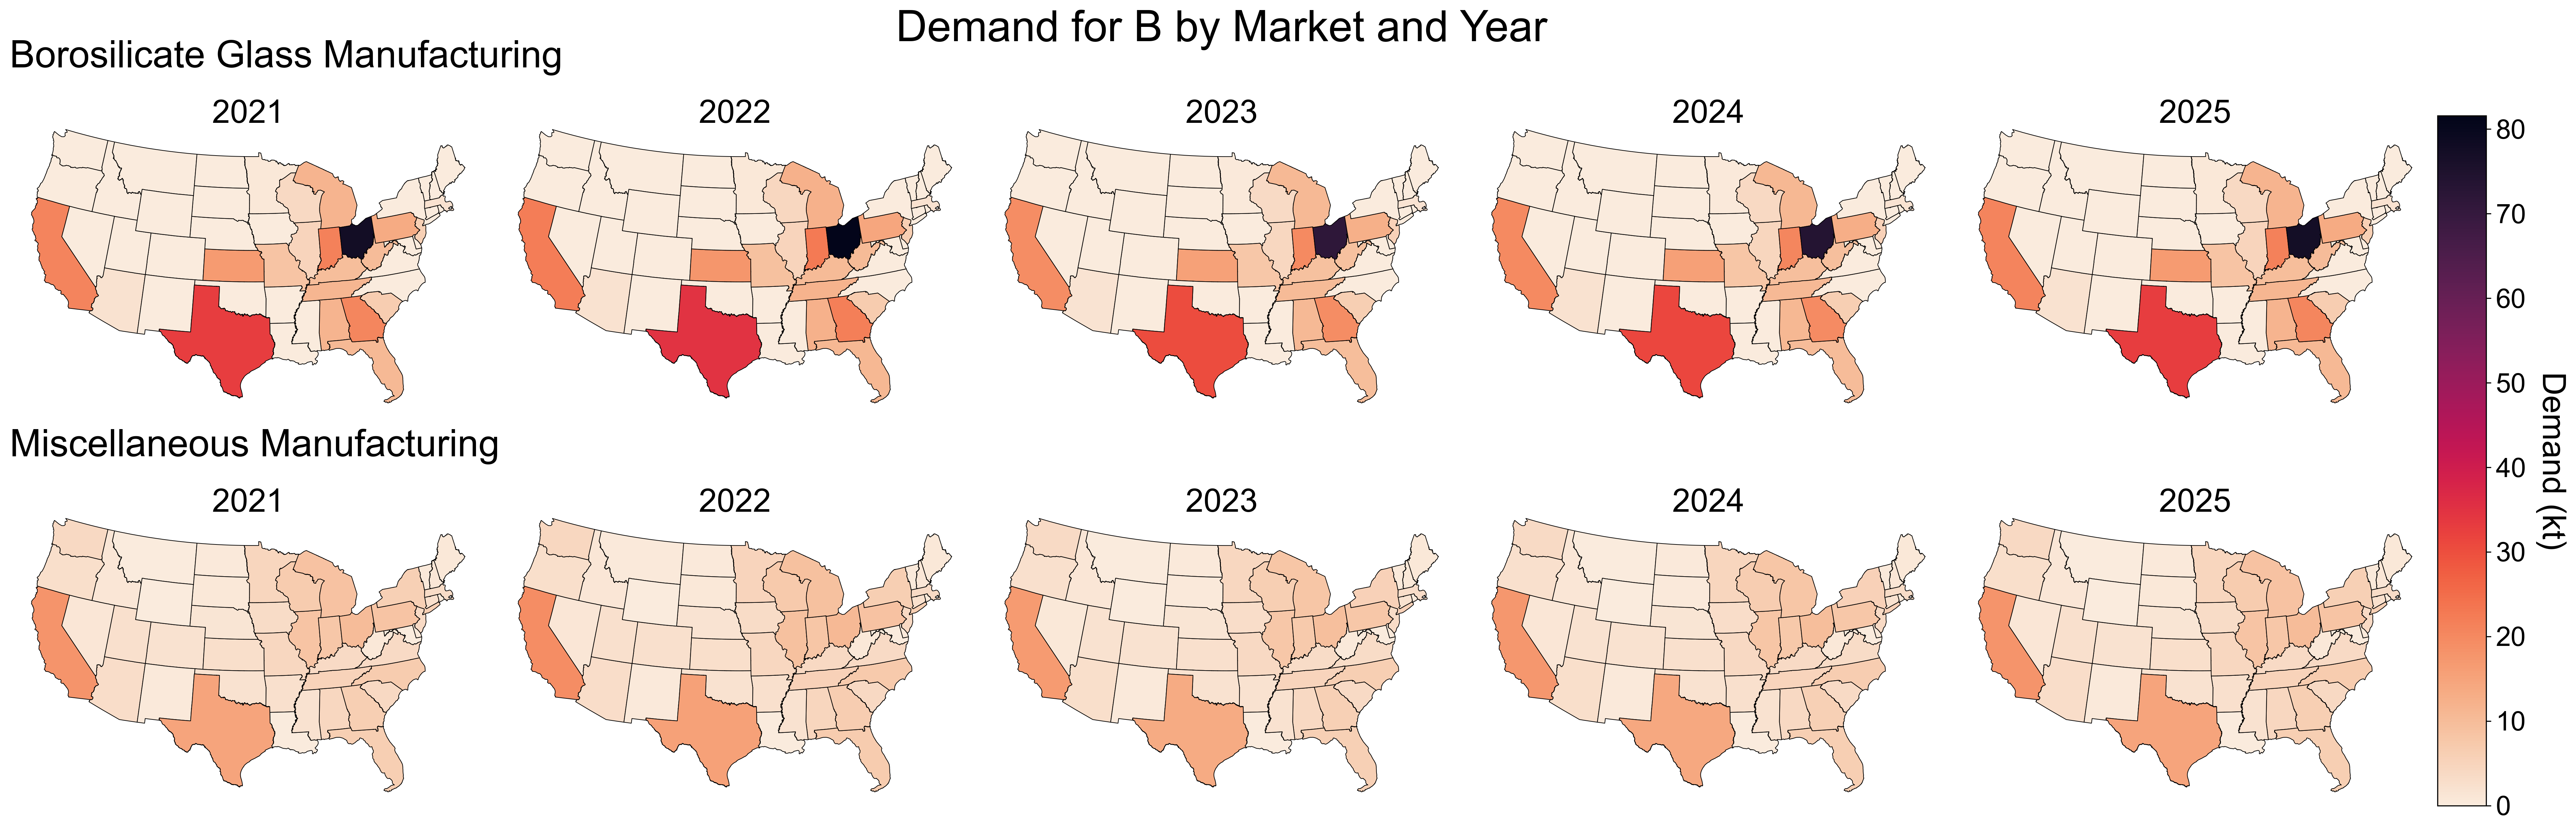

In [114]:
bp = 'B'
fig, axs, cbar = plot_demand_results(bp)

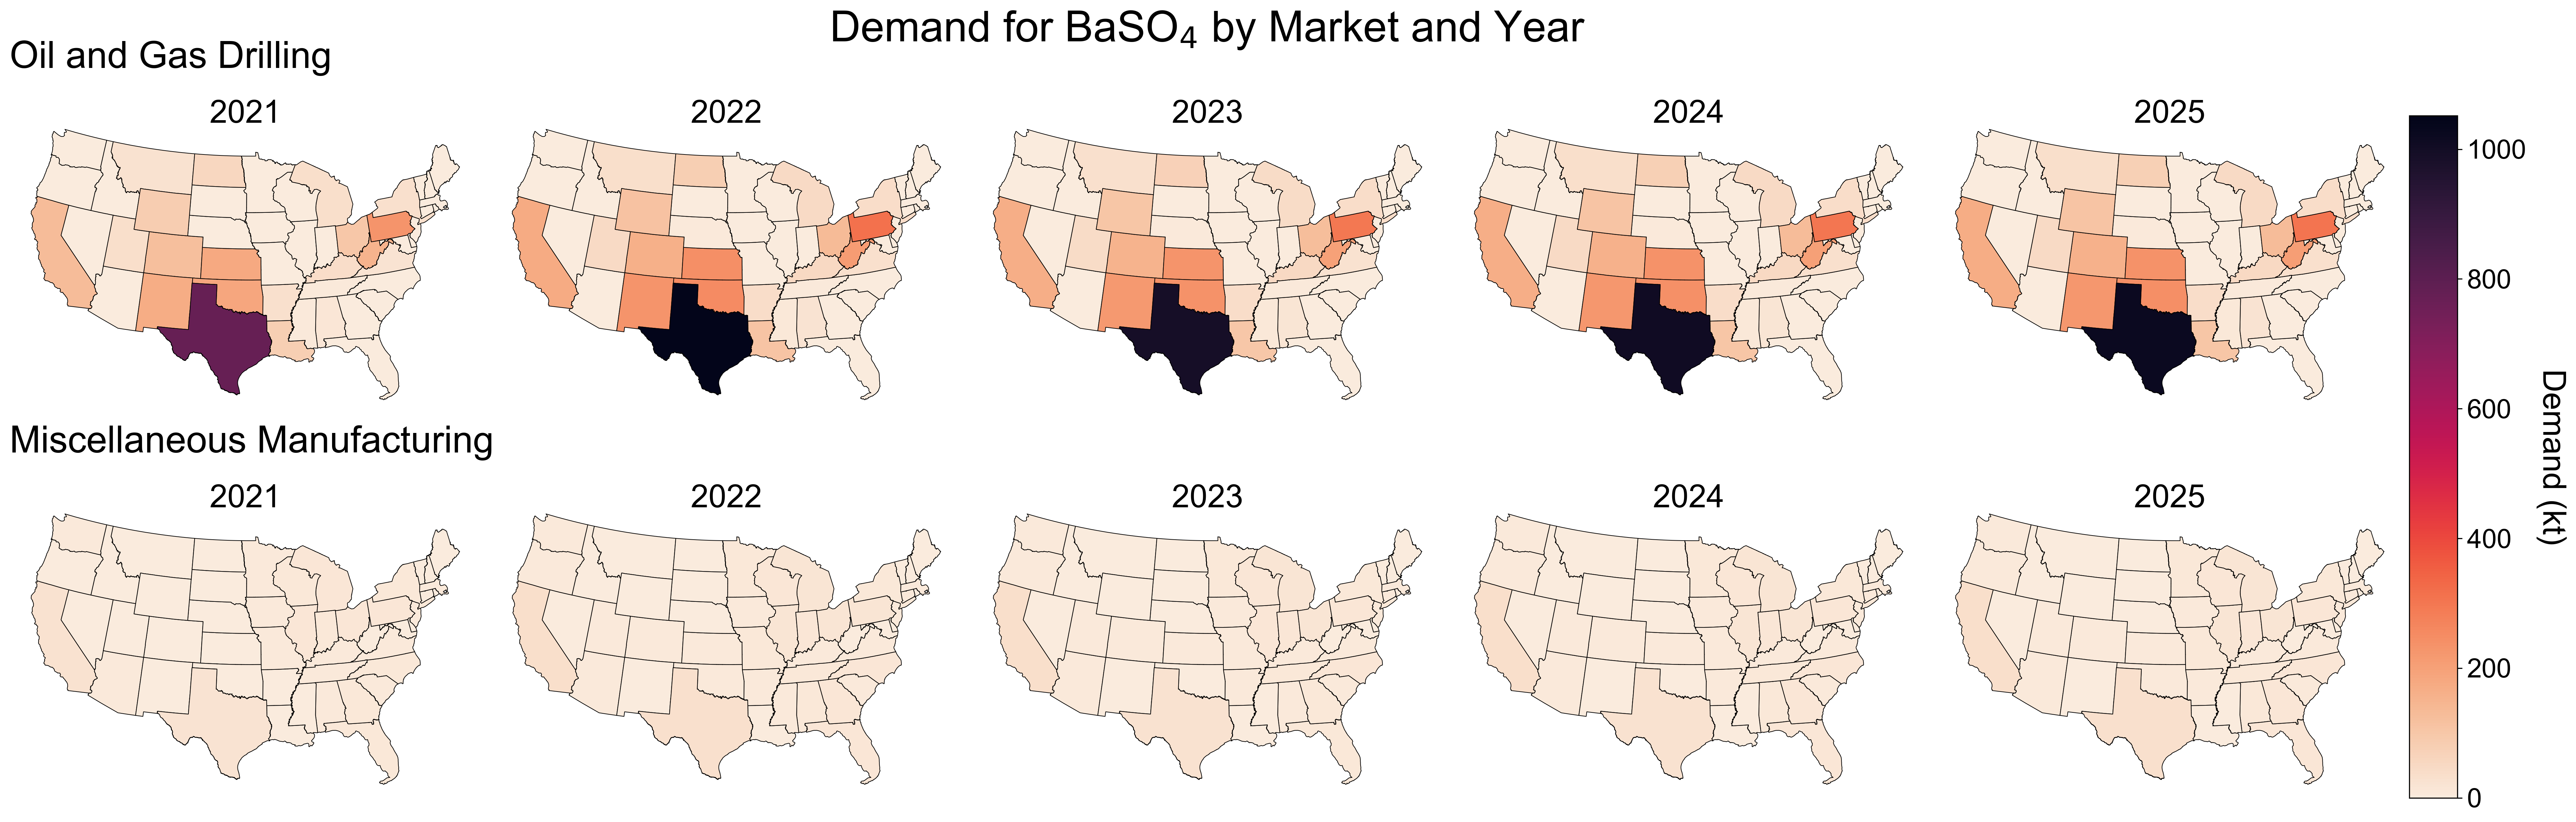

In [115]:
bp = 'BaSO4'
fig, axs, cbar = plot_demand_results(bp)

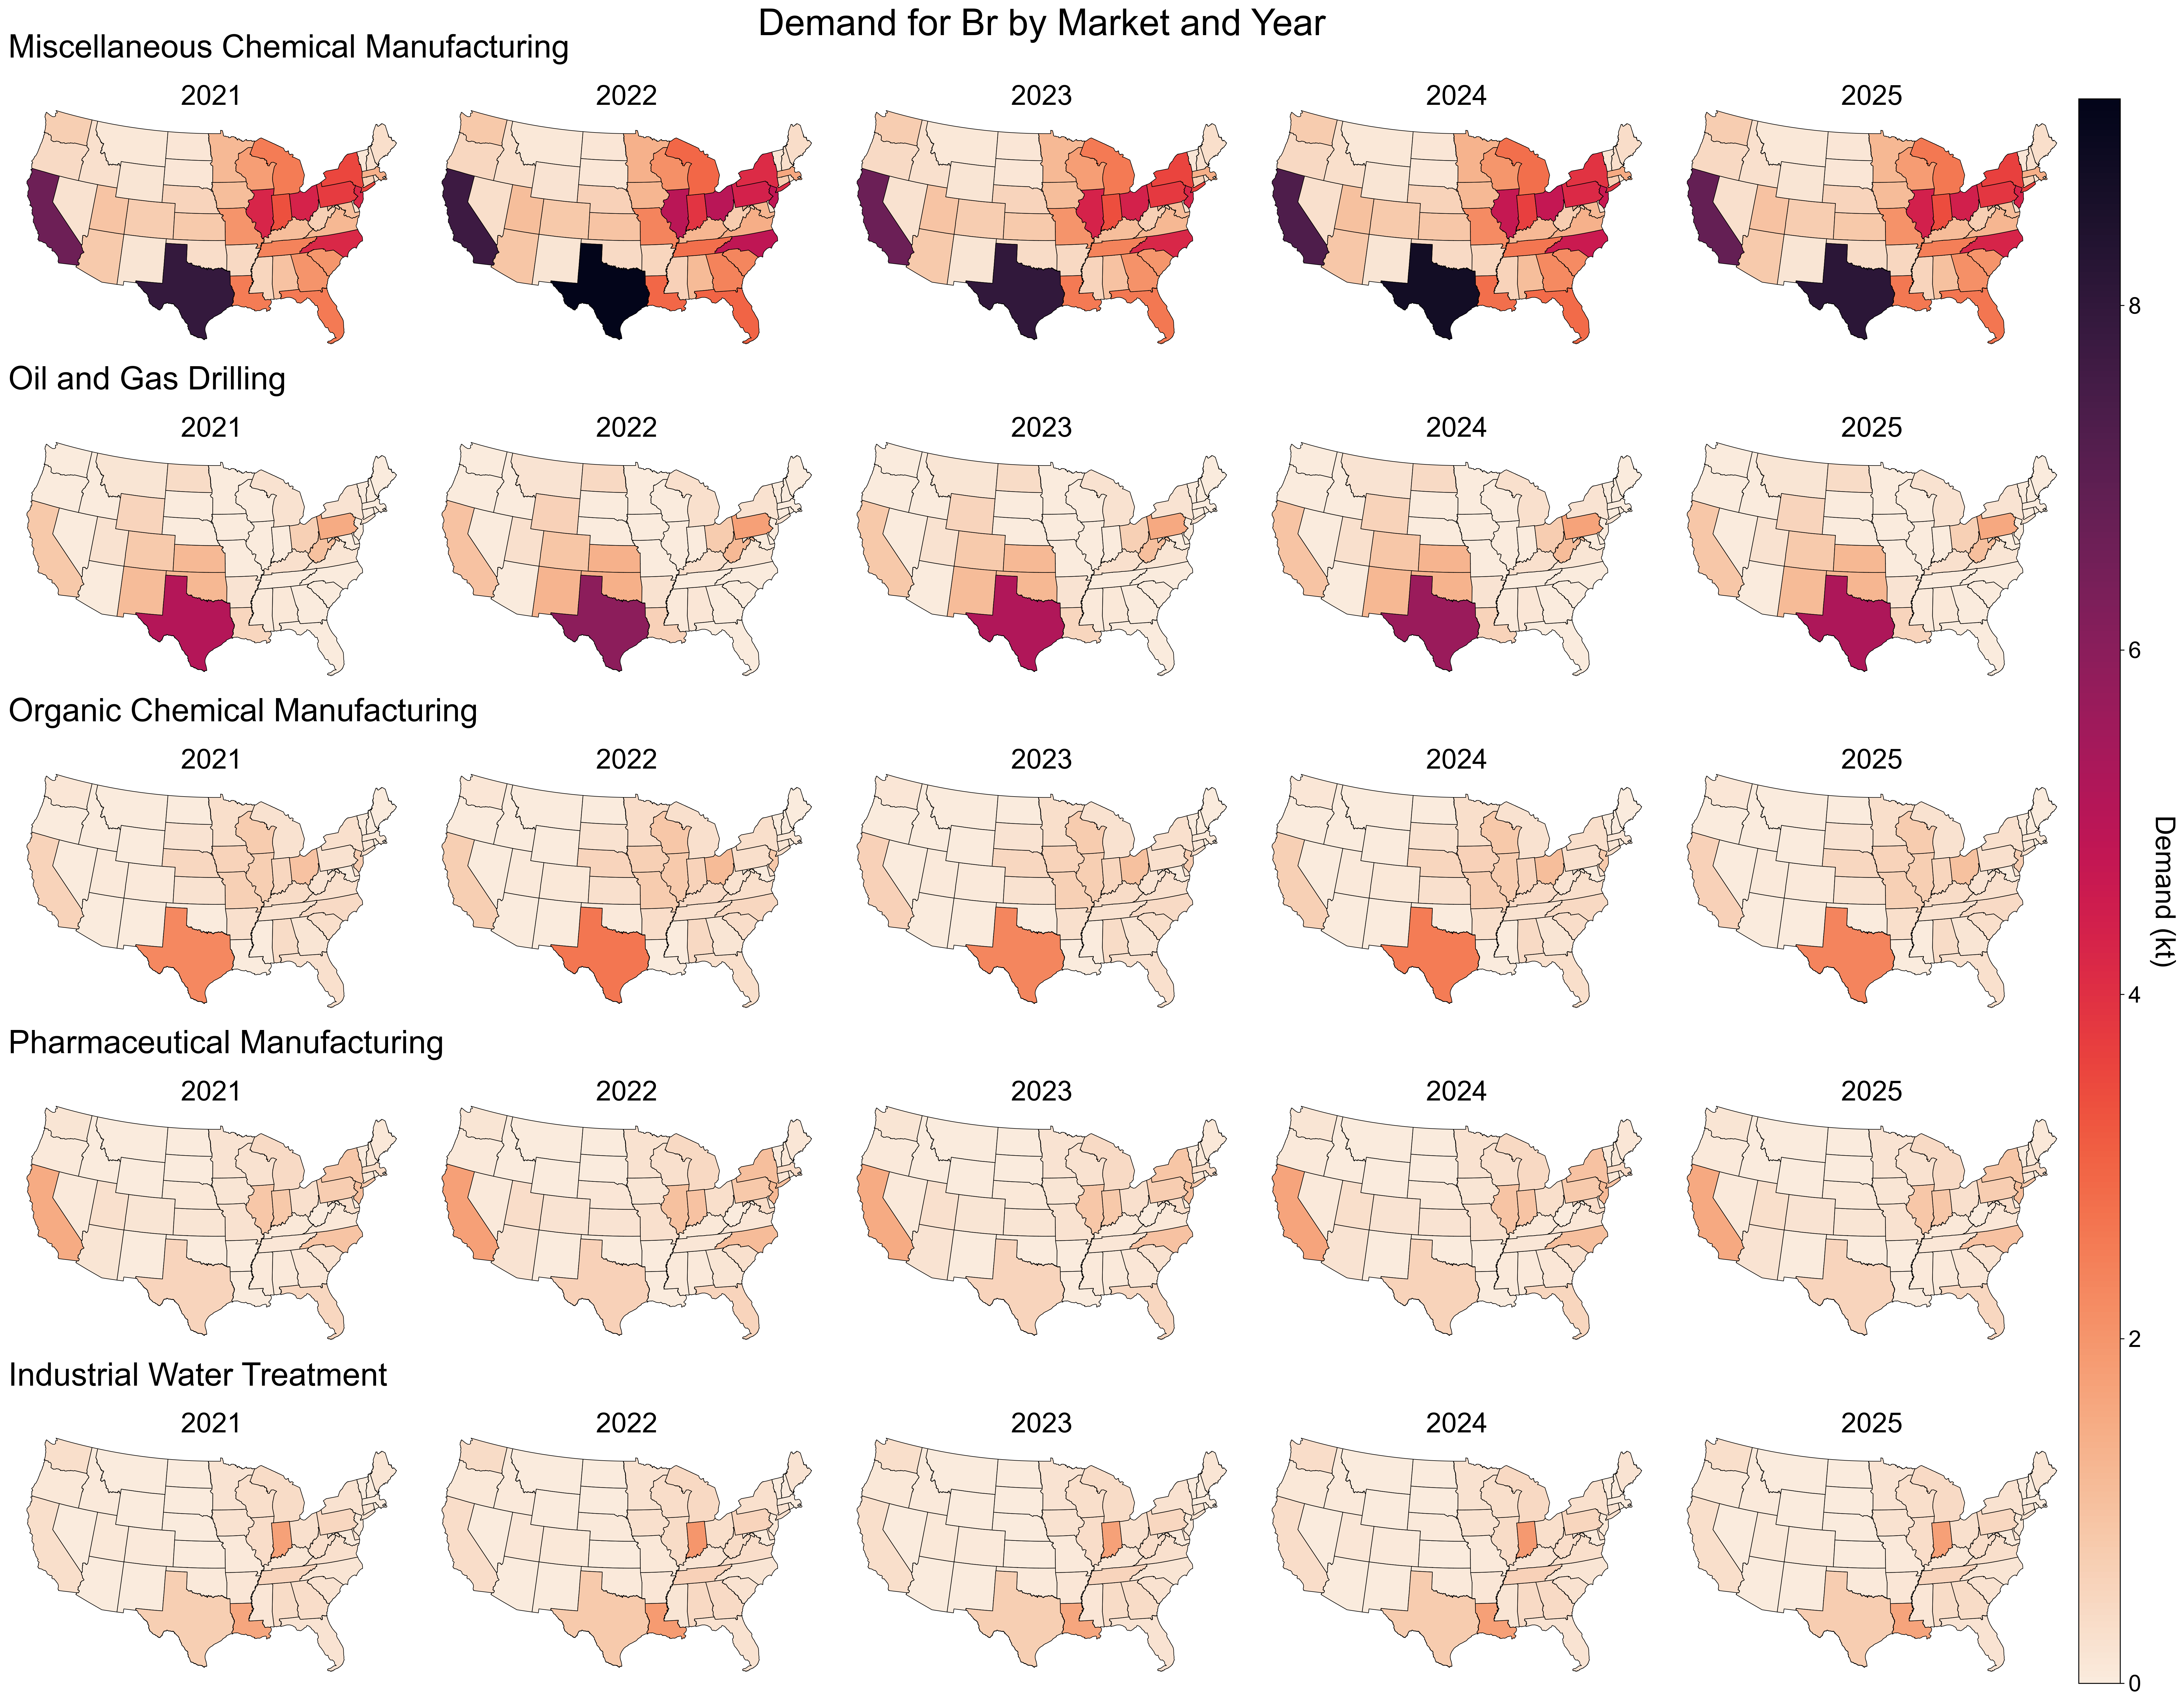

In [116]:
bp = 'Br'
fig, axs, cbar = plot_demand_results(bp)

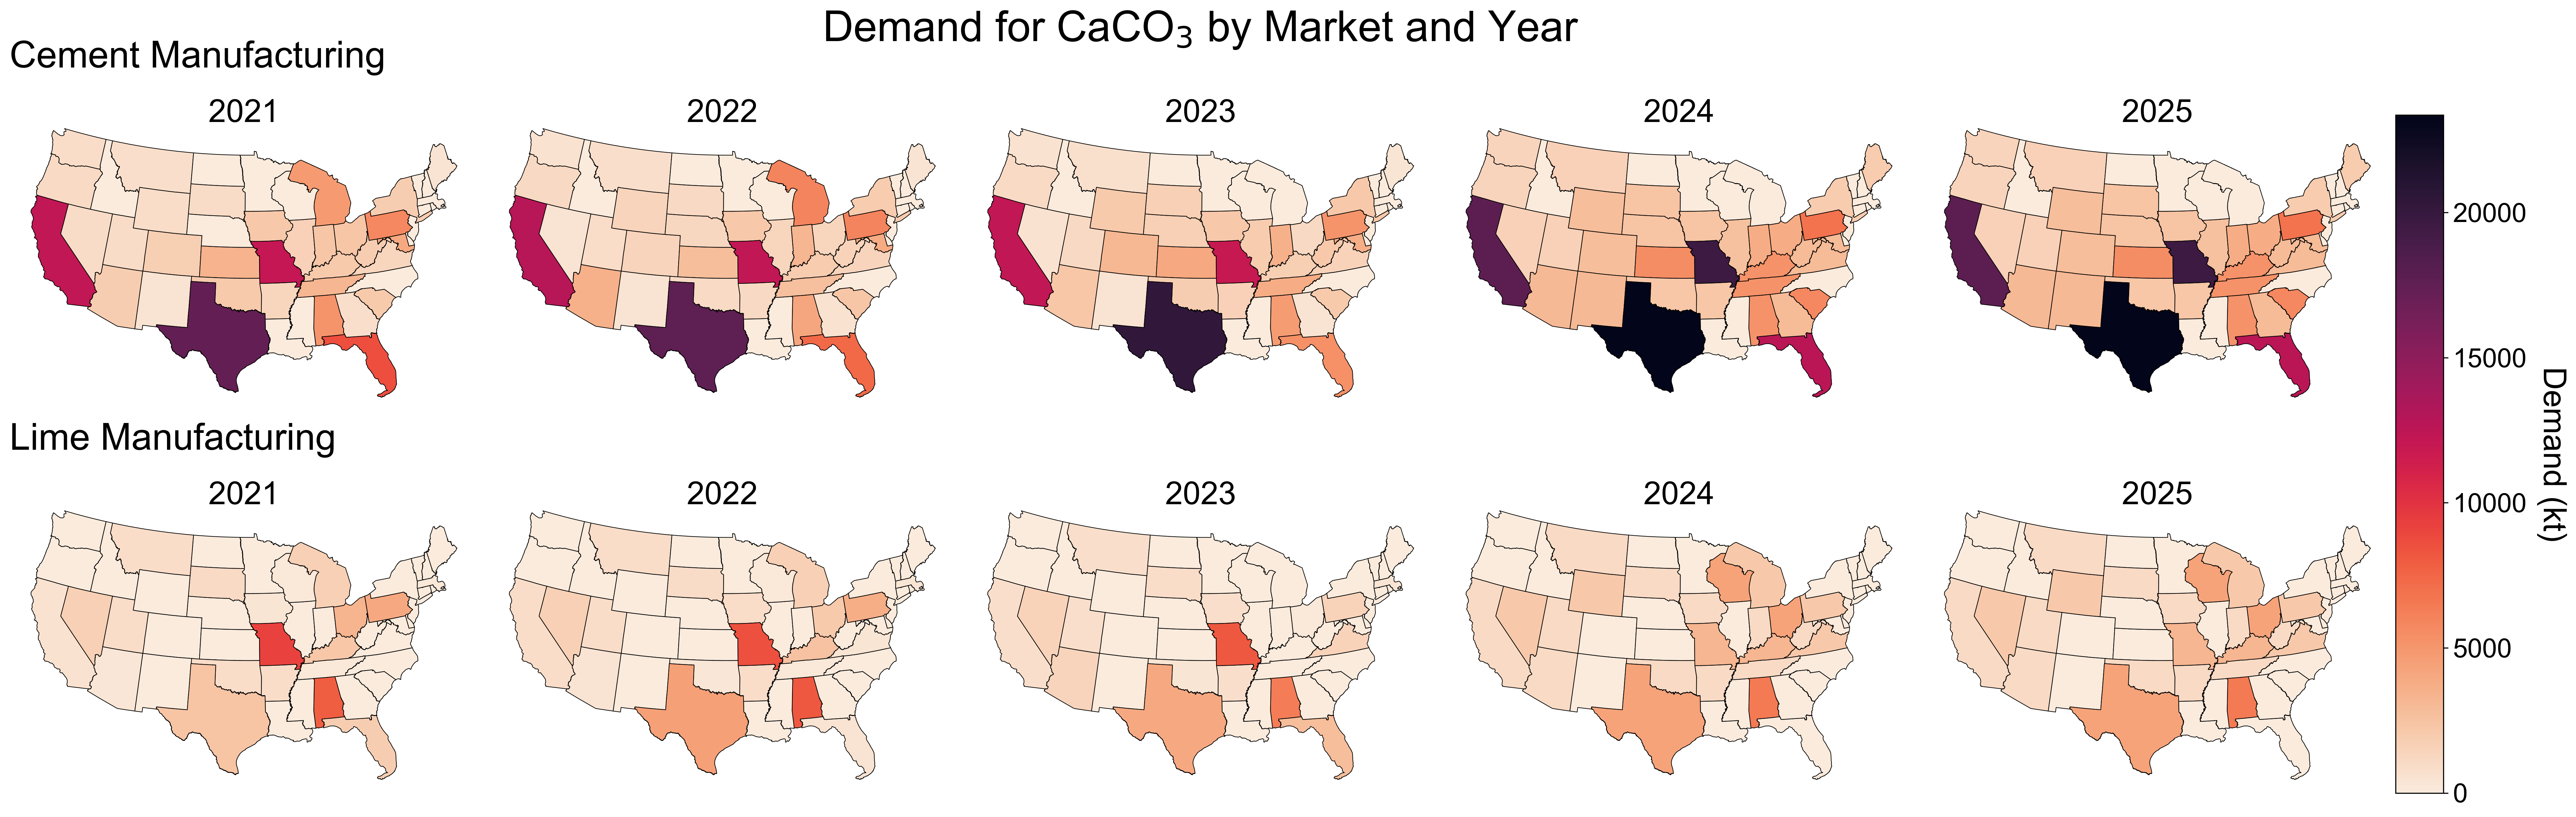

In [163]:
bp = 'CaCO3'
fig, axs, cbar = plot_demand_results(bp)